# Lab 2 - Data Modalities

In [2]:
import sys
!"{sys.executable}" -m pip install tabulate
!"{sys.executable}" -m pip install pandas
!"{sys.executable}" -m pip install matplotlib
!"{sys.executable}" -m pip install statsmodels
from tabulate import tabulate
import pandas as pd
import matplotlib.pyplot as plt

In this lab, we wll cover the common data modalities covered in the lecture, including tabular, JSON, time series and Geospatial data. There's a lot to cover, so we won't go into too much detail for any of these in this lab, but this should give you a good baseline to help you investigate these further in your other labs or assignment! 

## Tabular Data

Tabular data is one of the most common data modalities. It is expressed in a table-style format, with rows typically representing the individual objects or entities, and columns representing the attributes. For example, at a university, each row may represent an individual student, and each column may represent some characteristic of that student (e.g. name, date of birth, mark in a specific module, ...).

There are various ways to represent tabular data in Python. The simplest uses the default, built-in functionality of Python, without any additional libraries. For example:

In [3]:
student_data_1 = [{"Name": "John Smith", "Date of Birth": "01/03/2005", "CS950 Mark": "64"}, 
                  {"Name": "Sarah Harrison", "Date of Birth": "20/08/2006", "CS950 Mark": "87"}]

print(student_data_1)


[{'Name': 'John Smith', 'Date of Birth': '01/03/2005', 'CS950 Mark': '64'}, {'Name': 'Sarah Harrison', 'Date of Birth': '20/08/2006', 'CS950 Mark': '87'}]


Whilst the above is not a table in the strictest sense, its structure does somewhat mimic that of a table - each item (e.g. all information relating to _John Smith_) represents a row in the table, with the data's keys (e.g. _Name_ and _Date of Birth_) representing the columns. We could also represnt tabular data as a *list of lists*, like the below:

In [4]:
student_data_2 = [["Name", "Date of Birth", "CS950 Mark"], ["John Smith", "01/03/2005", "64"], ["Sarah Harrison", "20/08/2006", "87"]]

print(student_data_2)

print("The", student_data_2[0][1], "of", student_data_2[1][0], "is", student_data_2[1][1])

[['Name', 'Date of Birth', 'CS950 Mark'], ['John Smith', '01/03/2005', '64'], ['Sarah Harrison', '20/08/2006', '87']]
The Date of Birth of John Smith is 01/03/2005


As you can see above, we have represented our data as a list of lists, where each sub-list represents one specific entity. We can then easily access each element of our data as long as we remember the positions of each specific piece of data (e.g. "student_data[0][0]" represents the piece of data in the list at position 0 (i.e. the column headings), and the data at position 0 within that list (i.e. "Name")).

We could convert our Python dictionaries/lists to a more traditional tabular format using Python's *tabulate* library, as below:

In [5]:
x = tabulate(student_data_2)
print(x)

--------------  -------------  ----------
Name            Date of Birth  CS950 Mark
John Smith      01/03/2005     64
Sarah Harrison  20/08/2006     87
--------------  -------------  ----------


Whilst we will not cover the tabulate library any further in this lab, you can find out more here: https://pypi.org/project/tabulate/.

The most common way to process and analyse tabular data in Python is through the use of Pandas dataframes. Pandas is a powerful library which for managing and performing analysis on tabular data.

A table in Pandas is known as a *DataFrame*. Let's create a DataFrame:

In [6]:
student_data_3 = [{"Name": "John Smith", "Date of Birth": "01/03/2005", "CS950 Mark": "64"}, {"Name": "Sarah Harrison", "Date of Birth": "20/08/2006", "CS950 Mark": "87"}]

df = pd.DataFrame(student_data_3)

print(df)

             Name Date of Birth CS950 Mark
0      John Smith    01/03/2005         64
1  Sarah Harrison    20/08/2006         87


From the above, you will see a more traditional table-like structure. Alternatively, we can enter data into a Pandas dataframe one column at a time directly into the pd.DataFrame function, e.g.:

In [7]:
df2 = pd.DataFrame({"Name": ["John Smith", "Sarah Harrison"], "Date of Birth": ["01/03/2025", "20/08/2006"], "CS950 Mark": ["64", "87"]})

print(df2)

             Name Date of Birth CS950 Mark
0      John Smith    01/03/2025         64
1  Sarah Harrison    20/08/2006         87


We can extract only specific information from our Pandas DataFrame. For example, to extract only the _CS950 Mark_ column:

In [8]:
print(df2["CS950 Mark"])

0    64
1    87
Name: CS950 Mark, dtype: str


If we know the position of our row, we can extract it using _iloc_:

In [8]:
print(df2.iloc[1])

Name             Sarah Harrison
Date of Birth        20/08/2006
CS950 Mark                   87
Name: 1, dtype: str


We could also extract by some index. Let's set the _Name_ field as the index, and then extract the row corresponding to Sarah Harrison:

In [9]:
df2.set_index("Name", inplace=True)
print(df2.loc["Sarah Harrison"])

Date of Birth    20/08/2006
CS950 Mark               87
Name: Sarah Harrison, dtype: str


"inplace" above modifies the original dataframe, rather than creating a new one.

We can import data into a Pandas DataFrame. Download the data from here (https://github.com/mwaskom/seaborn-data/blob/master/iris.csv) by clicking the "Download raw file" button underneath the word "History", and then import the iris dataset via CSV.

In [10]:
from sklearn import datasets

iris = pd.read_csv('iris.csv')
print(iris)

     sepal_length  sepal_width  petal_length  petal_width    species
0             5.1          3.5           1.4          0.2     setosa
1             4.9          3.0           1.4          0.2     setosa
2             4.7          3.2           1.3          0.2     setosa
3             4.6          3.1           1.5          0.2     setosa
4             5.0          3.6           1.4          0.2     setosa
..            ...          ...           ...          ...        ...
145           6.7          3.0           5.2          2.3  virginica
146           6.3          2.5           5.0          1.9  virginica
147           6.5          3.0           5.2          2.0  virginica
148           6.2          3.4           5.4          2.3  virginica
149           5.9          3.0           5.1          1.8  virginica

[150 rows x 5 columns]


The above will create a Pandas DataFrame containing the iris dataset. We can extract some information about our dataframe in the following ways:

In [11]:
print(iris["sepal_length"].min())
print(iris["sepal_width"].max())
print(iris["species"].mode())


4.3
4.4
0        setosa
1    versicolor
2     virginica
Name: species, dtype: str


Q1: Why is print(iris["species"].mode()) returning three modes? 

More generally, we can use the following to provide some information about our DataFrame:

In [12]:
iris.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


You can see that the above provides a large amount of data about our DataFrame, including count (number of entires for that attribute, minimum, and quartiles).

Q2: What is "iris.info()" and "iris.dtypes" and how do they differ from iris.describe()?

We can select only the top few rows (e.g. 5) using the head() function:

In [13]:
print(iris.head(5))

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


We can discover the shape of a Pandas DataFrame using the shape attribute:

In [14]:
print(iris.shape)

(150, 5)


Thus, we can observe that iris is a Pandas DataFrame with 150 rows and 5 columns. We can select only certain rows of a Pandas DataFrame like so:

In [15]:
print(iris[iris["sepal_length"]<5])

     sepal_length  sepal_width  petal_length  petal_width     species
1             4.9          3.0           1.4          0.2      setosa
2             4.7          3.2           1.3          0.2      setosa
3             4.6          3.1           1.5          0.2      setosa
6             4.6          3.4           1.4          0.3      setosa
8             4.4          2.9           1.4          0.2      setosa
9             4.9          3.1           1.5          0.1      setosa
11            4.8          3.4           1.6          0.2      setosa
12            4.8          3.0           1.4          0.1      setosa
13            4.3          3.0           1.1          0.1      setosa
22            4.6          3.6           1.0          0.2      setosa
24            4.8          3.4           1.9          0.2      setosa
29            4.7          3.2           1.6          0.2      setosa
30            4.8          3.1           1.6          0.2      setosa
34            4.9   

Q3: Is there anything interesting that we can observe about the above? What does it tell us about the species with the smallest sepal length? How can we utilise Pandas' GroupBy function to determine the species with the smallest average sepal_length?

In [16]:
print(iris.groupby(by="species").mean())

            sepal_length  sepal_width  petal_length  petal_width
species                                                         
setosa             5.006        3.428         1.462        0.246
versicolor         5.936        2.770         4.260        1.326
virginica          6.588        2.974         5.552        2.026


## JSON Data

Unlike tabular data, JSON data has a hierarchical tree structure. Python has a built in json package, which can help us with some basic operations.

In [17]:
import json

We actually used some JSON-style data earlier, stored as a Python dictionary. Let's use it again:

In [18]:
student_data_1 = [{"Name": "John Smith", "Date of Birth": "01/03/2005", "CS950 Mark": "64"}, {"Name": "Sarah Harrison", "Date of Birth": "20/08/2006", "CS950 Mark": "87"}]

We can convert this data to the JSON format using the dumps() function:

In [19]:
x = json.dumps(student_data_1)
print(x)
print(type(student_data_1))
print(type(x))

[{"Name": "John Smith", "Date of Birth": "01/03/2005", "CS950 Mark": "64"}, {"Name": "Sarah Harrison", "Date of Birth": "20/08/2006", "CS950 Mark": "87"}]
<class 'list'>
<class 'str'>


This is not especially interesting, all it is doing is converting our dictionary to a JSON string. Let's use a more complex example to better understanding what dumps() is doing here:

In [20]:
student_data_3 = [{"Student ID": 100, "Current Student": True, "Department": "Computer Science", "Module Marks": [{"CS940": 65, "CS941": 72, "CS950": 55}] },{"Student ID": 101, "Current Student": False, "Department": "Computer Science", "Module Marks": [{"CS940": 42, "CS941": 88, "CS950": 61}] },{"Student ID": 102, "Current Student": True, "Department": "Psychology", "Module Marks": [{"CS940": 72, "CS941": 68, "CS950": 75}] }]

json_dumps_student_data = json.dumps(student_data_3)
print(json_dumps_student_data)

[{"Student ID": 100, "Current Student": true, "Department": "Computer Science", "Module Marks": [{"CS940": 65, "CS941": 72, "CS950": 55}]}, {"Student ID": 101, "Current Student": false, "Department": "Computer Science", "Module Marks": [{"CS940": 42, "CS941": 88, "CS950": 61}]}, {"Student ID": 102, "Current Student": true, "Department": "Psychology", "Module Marks": [{"CS940": 72, "CS941": 68, "CS950": 75}]}]


Q4: Look at the boolean values. Why are they now in lower case?

We can load the JSON-formatted string into a Python object using loads(), and then transform the JSON data into a flat table using json_normalize():

In [21]:
x = json.loads(json_dumps_student_data)

print(pd.json_normalize(x))

   Student ID  Current Student        Department  \
0         100             True  Computer Science   
1         101            False  Computer Science   
2         102             True        Psychology   

                                Module Marks  
0  [{'CS940': 65, 'CS941': 72, 'CS950': 55}]  
1  [{'CS940': 42, 'CS941': 88, 'CS950': 61}]  
2  [{'CS940': 72, 'CS941': 68, 'CS950': 75}]  


Q5: Consider the data below, which is JSON data representing customer information. You will see that one customer utilised an offer (getting all their shopping for free!), and another customer paid by cash. Hence, these keys ("offer_id" and "payment _method") are not visible in all entries. How can we convert this JSON data into structured tabular data?

In [22]:
customer_data = json.dumps([{"customer_id": 1, "sales": [{"store_id": 10, "sales_total": 100, "offer_id": 5},{"store_id": 8, "sales_total": 70, "payment_method": "05/10/2026"}]}, {"customer_id": 2, "sales": [{"store_id": 15, "sales_total": 54, "payment_method": "cash"}]}])
print(customer_data)

[{"customer_id": 1, "sales": [{"store_id": 10, "sales_total": 100, "offer_id": 5}, {"store_id": 8, "sales_total": 70, "payment_method": "05/10/2026"}]}, {"customer_id": 2, "sales": [{"store_id": 15, "sales_total": 54, "payment_method": "cash"}]}]


Q6: Does the data above look unusual in any way? If so, how would you fix it?

## Time Series Data

Let's import some time series data. We will use the Daily Climate Time Series dataset, which can be found here https://www.kaggle.com/datasets/sumanthvrao/daily-climate-time-series-data. We can import it using pd.read_csv().

In [23]:
time_series_df = pd.read_csv("DailyDelhiClimateTrain.csv")
# For simplicity, we are only using the training set CSV, which we will divide into training and testing sets later on in this notebook.
print(time_series_df.head())
print(time_series_df.dtypes)

         date   meantemp   humidity  wind_speed  meanpressure
0  2013-01-01  10.000000  84.500000    0.000000   1015.666667
1  2013-01-02   7.400000  92.000000    2.980000   1017.800000
2  2013-01-03   7.166667  87.000000    4.633333   1018.666667
3  2013-01-04   8.666667  71.333333    1.233333   1017.166667
4  2013-01-05   6.000000  86.833333    3.700000   1016.500000
date                str
meantemp        float64
humidity        float64
wind_speed      float64
meanpressure    float64
dtype: object


We can see here that the data type of "date" is actually a string. To perform time series analysis, we will need to ensure that the date information is converted to a datetime type. We can do this using Pandas' to_datetime function:

In [24]:
time_series_df["date"] = pd.to_datetime(time_series_df["date"])

print(time_series_df.head())
print(time_series_df.dtypes)

        date   meantemp   humidity  wind_speed  meanpressure
0 2013-01-01  10.000000  84.500000    0.000000   1015.666667
1 2013-01-02   7.400000  92.000000    2.980000   1017.800000
2 2013-01-03   7.166667  87.000000    4.633333   1018.666667
3 2013-01-04   8.666667  71.333333    1.233333   1017.166667
4 2013-01-05   6.000000  86.833333    3.700000   1016.500000
date            datetime64[us]
meantemp               float64
humidity               float64
wind_speed             float64
meanpressure           float64
dtype: object


Now that we have date/time information in our data frame, we can perform various different operations on our data. For example:

In [25]:
print(time_series_df["date"].min()) #Outputs the earliest datetime in the dataset.

2013-01-01 00:00:00


Calculate:
Q7. The length of our time series (i.e. the range of the datetimes). 
Q8. The average windspeed for each month in the dataset. TIP: You need to make sure you separate months from different years, e.g. there should be a different January average for each year, not one January average which covers all years.

We will cover data visualisation in a later lab, but we will briefly explore it now. We can use matplotlib to clearly plot time series data.

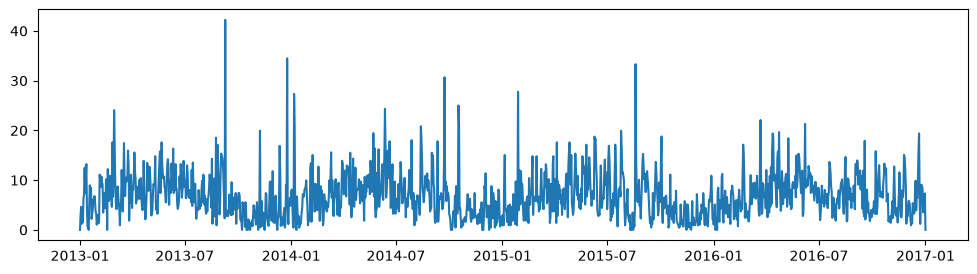

In [26]:
fig = plt.figure(figsize=(12,3))
plt.plot(time_series_df["date"],time_series_df["wind_speed"])
plt.show()

The data above is quite granlar, we may want to smooth it out a little. We can do this using a mix of group_by and to_period, like below:

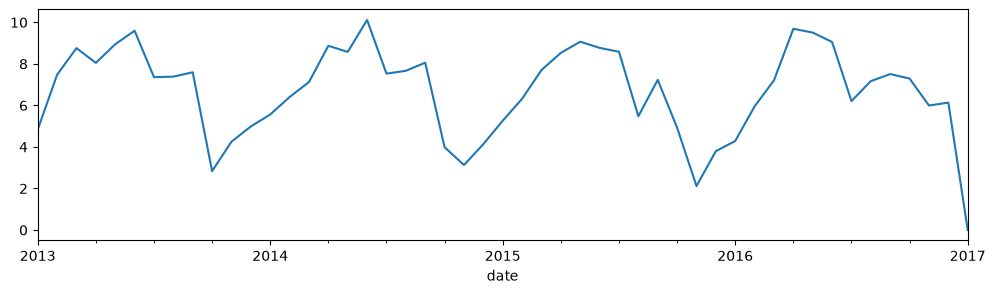

In [27]:
fig = plt.figure(figsize=(12,3))
time_series_df.groupby(time_series_df["date"].dt.to_period('M'))["wind_speed"].mean().plot()
plt.show()

Q9. What is the above code doing? How can you modify the code to make the figure more or less granular?

Another way that we can interpret the code is above is that you have *resampled* your data. Pandas actually has a built in function for this, resample().

Let's calculate the weekly average humidity:

In [28]:
weekly_avg_humidity = time_series_df.resample('W', on="date")[['humidity']].mean()
print(weekly_avg_humidity)

             humidity
date                 
2013-01-06  84.077778
2013-01-13  65.145238
2013-01-20  81.663265
2013-01-27  67.748299
2013-02-03  67.667347
...               ...
2016-12-04  62.631290
2016-12-11  70.672236
2016-12-18  61.808297
2016-12-25  66.346011
2017-01-01  82.139204

[209 rows x 1 columns]


The above is known as downsampling. We can also upsample, which involves inserting a set of additional values between existing data. For example, we can take our weekly average humidity, and upsample back to daily humidity:

In [29]:
pd.set_option('display.max_rows', 100)
daily_humidity_upsampled = weekly_avg_humidity.resample('D').ffill().reset_index()
print(daily_humidity_upsampled.head(100))

         date   humidity
0  2013-01-06  84.077778
1  2013-01-07  84.077778
2  2013-01-08  84.077778
3  2013-01-09  84.077778
4  2013-01-10  84.077778
5  2013-01-11  84.077778
6  2013-01-12  84.077778
7  2013-01-13  65.145238
8  2013-01-14  65.145238
9  2013-01-15  65.145238
10 2013-01-16  65.145238
11 2013-01-17  65.145238
12 2013-01-18  65.145238
13 2013-01-19  65.145238
14 2013-01-20  81.663265
15 2013-01-21  81.663265
16 2013-01-22  81.663265
17 2013-01-23  81.663265
18 2013-01-24  81.663265
19 2013-01-25  81.663265
20 2013-01-26  81.663265
21 2013-01-27  67.748299
22 2013-01-28  67.748299
23 2013-01-29  67.748299
24 2013-01-30  67.748299
25 2013-01-31  67.748299
26 2013-02-01  67.748299
27 2013-02-02  67.748299
28 2013-02-03  67.667347
29 2013-02-04  67.667347
30 2013-02-05  67.667347
31 2013-02-06  67.667347
32 2013-02-07  67.667347
33 2013-02-08  67.667347
34 2013-02-09  67.667347
35 2013-02-10  71.515476
36 2013-02-11  71.515476
37 2013-02-12  71.515476
38 2013-02-13  71.515476


You may have noticed that all this is doing is duplicating the weekly averages each day. If we wanted to try and interpolate, we can simply replace ffill() with interpolate(method='linear').

In [9]:
daily_humidity_interpolation = weekly_avg_humidity.resample('D').interpolate(method='linear').reset_index()
print(daily_humidity_interpolation.head(100))

NameError: name 'weekly_avg_humidity' is not defined

To perform more extensive time series analysis, we can utilise a model such as Exponential Smoothing. Exponential Smoothing is a model for time series analysis, especially for the forecasting of future values.

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error

time_series_df = pd.read_csv("DailyDelhiClimateTrain.csv")
# Load the dataset.

time_series_df["date"] = pd.to_datetime(time_series_df["date"])
# Convert the date into an datetime object, 

time_series_df = time_series_df.set_index("date") 
# Set the date column as the index (needed for time series analysis) 

time_series_df.index.freq = 'D'
# Set the frequency of the data to daily.

train = time_series_df.iloc[:-365]
test = time_series_df.iloc[-365:]
# Train the model on everything except the final year, test on the final year.

model = ExponentialSmoothing(train["humidity"],trend="add",seasonal="add",seasonal_periods=365)
results = model.fit()
# Define and train the model.

forecast = results.forecast(steps=365)
# Forecast 365 days into the future.

comparison = pd.DataFrame({"actual": test["humidity"], "forecast": forecast })
# Combine the real and forecast values into a single data frame.

plt.plot(comparison)
plt.show()
# Create a plot comparing the real and forecast values.

naive = train["humidity"].iloc[-365:].values
# Our naive forecast takes the final year of the training data and assumes that the forecast period will be identical to it.
good_mae = mean_absolute_error(test["humidity"],forecast)
print(f"Good MAE = {good_mae:.2f}")
naive_mae = mean_absolute_error(test["humidity"],naive)
print(f"Naive MAE = {naive_mae:.2f}")
# Print the Good MAE (i.e. the mean absolute error calculated by comparing the true values to the forecast) and the Naive MAE (i.e. the mean absolute error calculated by comparting the true values to simply the previous 365 days.)


You should fine that the Good MAE is lower than the Naive MAE, demonstrating that we have minimised our error by utilising time series analysis versus simply assuming the final year will be identical to the penultimate year.

# Exercises

1. If you have any time remaining, attempt to find some time series data (e.g. on Kaggle) and see if you can build a high-quality time series analysis model (you may want to explore _ARIMA_).

# Bibliography

1. Pandas, 2026. What kind of data does pandas handle?. Available at: https://pandas.pydata.org/docs/getting_started/intro_tutorials/01_table_oriented.html (Accessed: 07 October 2026).
2. Pandas, 2026. How do I read and write tabular data?. Available at: https://pandas.pydata.org/docs/getting_started/intro_tutorials/02_read_write.html (Accessed: 07 October 2026).
3. Pandas, 2026. How do I select a subset of a DataFrame?. Available at: https://pandas.pydata.org/docs/getting_started/intro_tutorials/03_subset_data.html (Accessed: 07 October 2026).
4. Pandas, 2026. Categorical data. Available at: https://pandas.pydata.org/docs/user_guide/categorical.html (Accessed: 07 October 2026).
5. Pandas, 2026. pandas.json_normalize. Available at: https://pandas.pydata.org/docs/reference/api/pandas.json_normalize.html (Accessed: 07 October 2026).
6. Pandas, 2026. pandas.Series.resample. Available at: https://pandas.pydata.org/docs/reference/api/pandas.Series.resample.html (Accessed: 07 October 2026).